In [3]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [5]:
GROUP = "C8"
DTYPE="CMMS"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C8_10,30,"[DATA/TRAINING/C8/C8_10/IMG_8678.HEIC, DATA/TR..."
1,C8_11,25,"[DATA/TRAINING/C8/C8_11/IMG_8730.HEIC, DATA/TR..."
2,C8_12,25,"[DATA/TRAINING/C8/C8_12/IMG_8761.HEIC, DATA/TR..."
3,C8_13,25,"[DATA/TRAINING/C8/C8_13/IMG_8793.HEIC, DATA/TR..."
4,C8_14,25,"[DATA/TRAINING/C8/C8_14/IMG_8823.HEIC, DATA/TR..."
5,C8_15,26,"[DATA/TRAINING/C8/C8_15/IMG_8855.HEIC, DATA/TR..."
6,C8_16,25,"[DATA/TRAINING/C8/C8_16/IMG_8886.HEIC, DATA/TR..."


In [6]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [7]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [8]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_8907.HEIC')

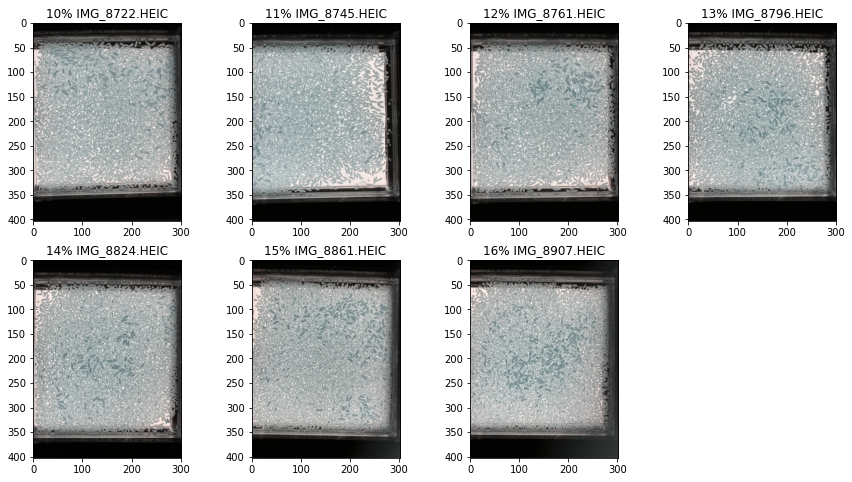

In [9]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [10]:
def color_moments(image):
    # Split the channels - h,s,v
    h, s, v = cv2.split(image)
    # Initialize the color feature
    color_feature = []
    # N = h.shape[0] * h.shape[1]
    
    # The first central moment - average
    h_mean = np.mean(h)  # np.sum(h)/float(N)
    s_mean = np.mean(s)  # np.sum(s)/float(N)
    v_mean = np.mean(v)  # np.sum(v)/float(N)
    color_feature.extend([h_mean, s_mean, v_mean])
    
    # The second central moment - standard deviation
    h_std = np.std(h)  # np.sqrt(np.mean(abs(h - h.mean())**2))
    s_std = np.std(s)  # np.sqrt(np.mean(abs(s - s.mean())**2))
    v_std = np.std(v)  # np.sqrt(np.mean(abs(v - v.mean())**2))
    color_feature.extend([h_std, s_std, v_std])
    
    # The third central moment - the third root of the skewness
    h_skewness = np.mean(abs(h - h.mean())**3)
    s_skewness = np.mean(abs(s - s.mean())**3)
    v_skewness = np.mean(abs(v - v.mean())**3)
    h_thirdMoment = h_skewness**(1./3)
    s_thirdMoment = s_skewness**(1./3)
    v_thirdMoment = v_skewness**(1./3)
    color_feature.extend([h_thirdMoment, s_thirdMoment, v_thirdMoment])
    """
    # The second central moment - standard deviation
    hist_h = cv2.calcHist([h], [0], None, [256], [0, 256])
    hist_h = cv2.normalize(hist_h, hist_h, 0, 1, cv2.NORM_MINMAX)

    hist_s = cv2.calcHist([s], [0], None, [256], [0, 256])
    hist_s = cv2.normalize(hist_s, hist_s, 0, 1, cv2.NORM_MINMAX)

    hist_v = cv2.calcHist([v], [0], None, [256], [0, 256])
    hist_v = cv2.normalize(hist_v, hist_v, 0, 1, cv2.NORM_MINMAX)

    h_skew = kurtosis(hist_h)  
    s_skew = kurtosis(hist_s) 
    v_skew = kurtosis(hist_v) 
    color_feature.extend([h_skew[0], s_skew[0], v_skew[0]])
    
    
    h_kts = kurtosis(hist_h)  
    s_kts = kurtosis(hist_s) 
    v_kts = kurtosis(hist_v) 
    color_feature.extend([h_kts[0], s_kts[0], v_kts[0]])
    
    # The second central moment - standard deviation
    h_ent = entropy(hist_h)  
    s_ent = entropy(hist_s) 
    v_ent = entropy(hist_v) 
    color_feature.extend([h_ent, s_ent, v_ent])
    """
    return color_feature

In [156]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [157]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,55.351296,38.835278,130.523241,34.715957,47.094045,71.697283,37.380040,61.695984,79.564801,3,120,90,3,IMG_8678.HEIC,10
1,57.983704,34.456574,130.624259,33.026343,49.044649,69.023120,35.444524,64.722392,77.626952,3,120,90,3,IMG_8679.HEIC,10
2,58.444074,36.616574,131.604907,36.212999,47.518002,68.860741,38.335389,64.281978,77.613803,3,120,90,3,IMG_8680.HEIC,10
3,52.483704,37.625463,133.002685,33.502423,47.792051,69.519304,36.766633,63.030040,78.705862,3,120,90,3,IMG_8682.HEIC,10
4,60.007593,33.604722,132.099352,34.911135,49.181606,69.227805,37.013929,65.806520,78.013292,3,120,90,3,IMG_8686.HEIC,10
5,57.945833,33.950741,131.814537,33.257276,50.582228,72.559050,35.806352,66.338894,80.433190,3,120,90,3,IMG_8693.HEIC,10
6,61.471852,33.536296,131.867963,33.824579,48.791189,72.652423,35.866639,64.456099,80.536496,3,120,90,3,IMG_8701.HEIC,10
7,58.450370,35.350278,131.316296,33.957508,47.712028,74.558376,36.231431,62.945009,81.925833,3,120,90,3,IMG_8702.HEIC,10
8,57.337685,35.829167,131.771204,32.197207,48.971959,73.679246,34.704699,64.374526,81.420987,3,120,90,3,IMG_8703.HEIC,10
9,60.214259,33.388056,132.428056,32.728909,49.484817,72.329988,34.990109,65.183388,80.441076,3,120,90,3,IMG_8704.HEIC,10


# Classification

In [158]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [159]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [160]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [161]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [162]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [163]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.631579,0.714286,0.595238,0.649351,CMMS,C8,RF_C,3,120,90,3
1,2,0.888889,0.942857,0.904762,0.923417,CMMS,C8,RF_C,3,120,90,3
2,3,0.666667,0.740476,0.690476,0.714603,CMMS,C8,RF_C,3,120,90,3
3,4,0.833333,0.907143,0.809524,0.855558,CMMS,C8,RF_C,3,120,90,3
4,5,0.777778,0.773810,0.785714,0.779716,CMMS,C8,RF_C,3,120,90,3
5,6,0.666667,0.654762,0.666667,0.660661,CMMS,C8,RF_C,3,120,90,3
6,7,0.666667,0.595238,0.666667,0.628931,CMMS,C8,RF_C,3,120,90,3
7,8,0.666667,0.847619,0.690476,0.761020,CMMS,C8,RF_C,3,120,90,3
8,9,0.666667,0.726190,0.714286,0.720189,CMMS,C8,RF_C,3,120,90,3
9,10,0.777778,0.833333,0.809524,0.821256,CMMS,C8,RF_C,3,120,90,3


In [164]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C8,RF_C,0.724269,0.733333,0.75147,0.773571


### MLP Classifier

In [165]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [166]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.823810,0.809524,0.816604,CMMS,C8,MLP_C,3,120,90,3
1,2,0.666667,0.750000,0.666667,0.705882,CMMS,C8,MLP_C,3,120,90,3
2,3,0.722222,0.773810,0.738095,0.755531,CMMS,C8,MLP_C,3,120,90,3
3,4,0.555556,0.666667,0.547619,0.601307,CMMS,C8,MLP_C,3,120,90,3
4,5,0.666667,0.666667,0.619048,0.641975,CMMS,C8,MLP_C,3,120,90,3
5,6,0.722222,0.833333,0.738095,0.782828,CMMS,C8,MLP_C,3,120,90,3
6,7,0.777778,0.821429,0.785714,0.803175,CMMS,C8,MLP_C,3,120,90,3
7,8,0.611111,0.630952,0.642857,0.636849,CMMS,C8,MLP_C,3,120,90,3
8,9,0.666667,0.735714,0.690476,0.712378,CMMS,C8,MLP_C,3,120,90,3
9,10,0.666667,0.750000,0.690476,0.719008,CMMS,C8,MLP_C,3,120,90,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C8,MLP_C,0.684503,0.692857,0.717554,0.745238


### XGBoost Classifier

In [169]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [170]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.842105,0.880952,0.833333,0.856481,CMMS,C8,XGB_C,3,120,90,3
1,2,0.666667,0.642857,0.690476,0.665816,CMMS,C8,XGB_C,3,120,90,3
2,3,0.722222,0.642857,0.761905,0.697337,CMMS,C8,XGB_C,3,120,90,3
3,4,0.611111,0.719048,0.595238,0.651311,CMMS,C8,XGB_C,3,120,90,3
4,5,0.666667,0.559524,0.666667,0.608414,CMMS,C8,XGB_C,3,120,90,3
5,6,0.722222,0.750000,0.738095,0.744000,CMMS,C8,XGB_C,3,120,90,3
6,7,0.722222,0.823810,0.738095,0.778600,CMMS,C8,XGB_C,3,120,90,3
7,8,0.611111,0.630952,0.595238,0.612575,CMMS,C8,XGB_C,3,120,90,3
8,9,0.611111,0.778912,0.642857,0.704375,CMMS,C8,XGB_C,3,120,90,3
9,10,0.777778,0.821429,0.761905,0.790548,CMMS,C8,XGB_C,3,120,90,3


In [171]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C8,XGB_C,0.695322,0.702381,0.710946,0.725034


# External validation

In [172]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C8_10,5,"[DATA/TEST/C8/C8_10/IMG_8685.HEIC, DATA/TEST/C..."
1,C8_11,5,"[DATA/TEST/C8/C8_11/IMG_8732.HEIC, DATA/TEST/C..."
2,C8_12,5,"[DATA/TEST/C8/C8_12/IMG_8762.HEIC, DATA/TEST/C..."
3,C8_13,5,"[DATA/TEST/C8/C8_13/IMG_8792.HEIC, DATA/TEST/C..."
4,C8_14,5,"[DATA/TEST/C8/C8_14/IMG_8827.HEIC, DATA/TEST/C..."
5,C8_15,5,"[DATA/TEST/C8/C8_15/IMG_8854.HEIC, DATA/TEST/C..."
6,C8_16,5,"[DATA/TEST/C8/C8_16/IMG_8901.HEIC, DATA/TEST/C..."


In [173]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [174]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [175]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,52.864907,38.101296,132.545741,33.108380,47.674901,70.044068,36.259860,62.530485,78.998754,3,120,90,3,IMG_8685.HEIC,10
1,59.841852,32.395370,132.228519,33.200873,49.913126,69.496528,35.515230,67.432651,78.144562,3,120,90,3,IMG_8687.HEIC,10
2,60.433981,32.185463,132.630463,32.870279,49.937957,70.748246,35.130557,66.126923,79.200364,3,120,90,3,IMG_8688.HEIC,10
3,56.517500,36.446944,133.698611,33.763426,49.765656,74.890007,36.397240,64.857312,82.670789,3,120,90,3,IMG_8696.HEIC,10
4,52.020463,31.487778,132.730741,30.335364,49.739844,71.539403,33.880464,65.837073,79.656669,3,120,90,3,IMG_8699.HEIC,10
0,54.609722,35.057778,131.613333,31.995934,49.393657,75.238378,34.929771,65.133587,82.484882,3,120,90,3,IMG_8732.HEIC,11
1,57.537870,36.531574,131.136667,32.950539,49.441581,75.651472,35.387699,64.740829,82.848382,3,120,90,3,IMG_8735.HEIC,11
2,56.533148,35.531944,131.001019,31.693062,49.594699,75.434131,34.303009,65.063826,82.485552,3,120,90,3,IMG_8737.HEIC,11
3,56.897963,31.640000,130.892963,32.907108,49.678642,73.189480,35.650301,66.032668,80.733374,3,120,90,3,IMG_8739.HEIC,11
4,55.205185,34.840926,130.571296,33.329304,49.242167,75.944772,36.235060,64.935701,82.860260,3,120,90,3,IMG_8740.HEIC,11


In [176]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [177]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [178]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [179]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [180]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.20      0.29         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.40      0.80      0.53         5
     Class 3       0.80      0.80      0.80         5
     Class 4       1.00      1.00      1.00         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.75      0.60      0.67         5

    accuracy                           0.74        35
   macro avg       0.78      0.74      0.74        35
weighted avg       0.78      0.74      0.74        35



## MLP

In [181]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [182]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.57      0.80      0.67         5
     Class 3       0.60      0.60      0.60         5
     Class 4       0.43      0.60      0.50         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.60      0.60      0.60         5

    accuracy                           0.63        35
   macro avg       0.60      0.63      0.61        35
weighted avg       0.60      0.63      0.61        35



## XGBC

In [183]:
y_pred = modelXGBC.predict(X_test_scale) 

In [184]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.20      0.29         5
     Class 1       1.00      0.80      0.89         5
     Class 2       0.40      0.80      0.53         5
     Class 3       0.67      0.80      0.73         5
     Class 4       1.00      1.00      1.00         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.75      0.60      0.67         5

    accuracy                           0.71        35
   macro avg       0.76      0.71      0.71        35
weighted avg       0.76      0.71      0.71        35

